# Imports

In [1]:
import numpy as np
from sklearn import datasets as ds
from sklearn import cluster as ct
from sklearn import metrics as mt
from matplotlib import pyplot as plt

# Gerando dados sintéticos

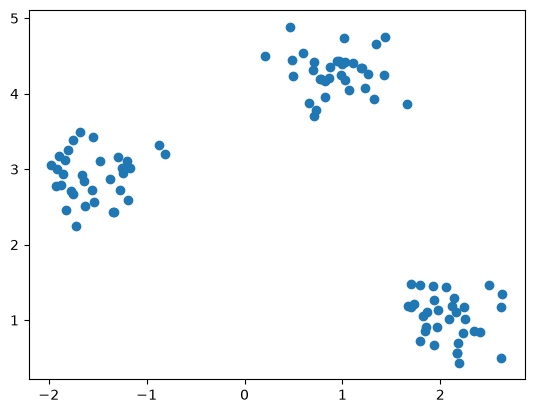

In [23]:
x, y = ds.make_blobs(
    n_samples=100,
    n_features=2,
    centers=3,
    cluster_std=0.3,
    random_state=0
)

plt.scatter(x[:, 0], x[:, 1])

# Looping do Elbow Method

In [7]:
clusters = np.arange(2, 11, 1)
ss_list = []

for k in clusters:
    kmeans = ct.KMeans(n_clusters=k, init='random', n_init=10, random_state=0)

    labels = kmeans.fit_predict(x)

    ss_avg = mt.silhouette_score(x, labels)

    ss_list.append(ss_avg)



# Plotando a curva desse Looping

Text(0, 0.5, 'SS_AVG')

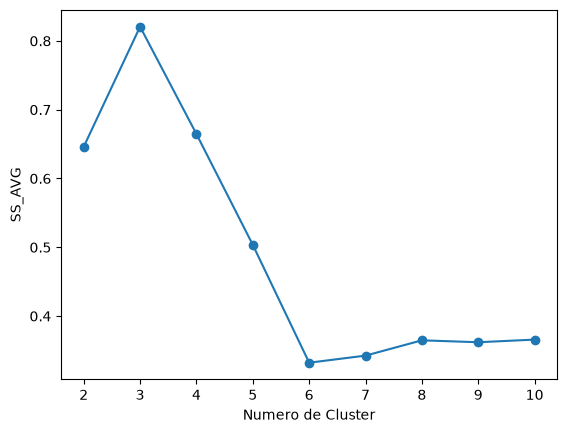

In [8]:
plt.plot(clusters, ss_list, marker='o')
plt.xlabel('Numero de Cluster')
plt.ylabel('SS_AVG')

# Utilizando o melhor K (3) encontrado no looping

O melhor K é o valor 3


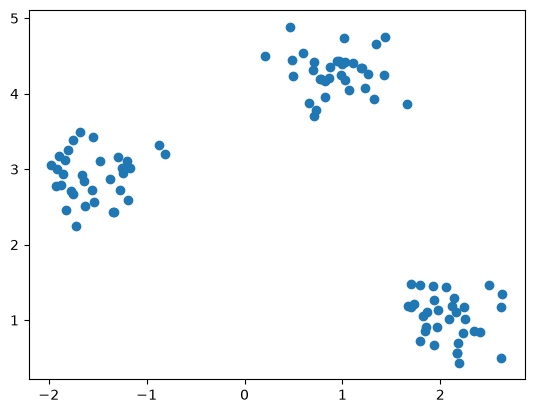

In [21]:
k = ss_list.index(max(ss_list)) + 2
print(f'O melhor K é o valor {k}')

kmeans = ct.KMeans(n_clusters=k, init='random', n_init=10, random_state=0)

labels = kmeans.fit_predict(x)

ss_avg = mt.silhouette_score(x, labels)

plt.scatter(x[:, 0], x[:, 1])

# Plotando os cluster com o melhor K

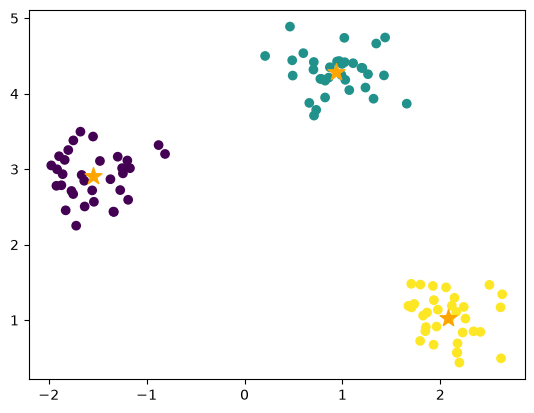

In [25]:
plt.scatter(x[:, 0], x[:, 1], c=labels)

for i in range(len(kmeans.cluster_centers_)):
    plt.scatter(kmeans.cluster_centers_[i, 0], kmeans.cluster_centers_[i, 1], marker='*', c='orange', s=160)